# Pré-Main: Estudo de Ablação de Data Augmentation

Objetivo: medir a contribuição real de cada transformação geométrica e fotométrica no detector YOLO (YOLO11n, `imgsz=640`, 60 épocas, seed 0).

- **Baseline (`none`)**: sem nenhuma augmentation.
- **Isolados (`+x`)**: apenas 1 transformação ligada por vez.
- **Completo (`all`)**: todas ligadas simultaneamente.
- **Leave-One-Out (`-x`)**: todas ligadas, exceto a transformação $x$ (mede sensibilidade e se alguma atrapalha o conjunto).

## 0. Pipeline de Execução dos Experimentos de Ablação

O bloco a seguir define a matriz sistemática de 16 experimentos de treinamento com o YOLO11n (`imgsz=640`, 60 épocas, batch=16, seed fixa).

Por padrão, `RUN_ABLATION_TRAINING = False` para utilizar os resultados pré-computados em `reports/ablation.csv`. Para re-executar os 16 treinos completos na GPU do zero, basta alternar a flag para `True`.

In [1]:
# Flag de controle: False para carregar histórico consolidado, True para re-treinar todos na GPU
RUN_ABLATION_TRAINING = False

In [2]:
from pathlib import Path
import pandas as pd
from ultralytics import YOLO

# Configuração do Pipeline de Treinamento de Ablação
ROOT = Path(".").resolve()
DATA = str((ROOT / "dataset/data.yaml").resolve())
RUNS = (ROOT / "runs/ablation").resolve()
BASE = dict(data=DATA, epochs=60, patience=60, imgsz=640, batch=16, seed=0,
            project=str(RUNS), exist_ok=True, plots=False, verbose=False)

OFF = dict(degrees=0, perspective=0, shear=0, scale=0, translate=0, fliplr=0, flipud=0,
           hsv_h=0, hsv_s=0, hsv_v=0, mosaic=0, mixup=0, erasing=0)
COMPONENTS = {
    "rot": {"degrees": 10},
    "persp": {"perspective": 0.0005},
    "shear": {"shear": 5},
    "scale_trans": {"scale": 0.5, "translate": 0.1},
    "flip": {"fliplr": 0.5},
    "color": {"hsv_h": 0.015, "hsv_s": 0.7, "hsv_v": 0.4},
    "mosaic": {"mosaic": 1.0},
}

def combo(names):
    cfg = dict(OFF)
    for n in names:
        cfg.update(COMPONENTS[n])
    return cfg

ALL = list(COMPONENTS)
CONFIGS = {"none": combo([])}
CONFIGS.update({f"+{n}": combo([n]) for n in ALL})
CONFIGS["all"] = combo(ALL)
CONFIGS.update({f"-{n}": combo([m for m in ALL if m != n]) for n in ALL})

def score(name):
    r = pd.read_csv(RUNS / name / "results.csv")
    r.columns = r.columns.str.strip()
    return dict(config=name,
                mAP50_last5=r["metrics/mAP50(B)"].tail(5).mean(),
                mAP50_95_last5=r["metrics/mAP50-95(B)"].tail(5).mean(),
                mAP50_95_best=r["metrics/mAP50-95(B)"].max(),
                epochs=len(r))

if RUN_ABLATION_TRAINING:
    print("Iniciando treinamento dos 16 modelos da matriz de ablação...")
    for name, cfg in CONFIGS.items():
        done = (RUNS / name / "results.csv").exists() and len(pd.read_csv(RUNS / name / "results.csv")) >= BASE["epochs"]
        if done:
            print(f"[skip] {name}")
            continue
        print(f"[run ] {name}")
        YOLO("yolo11n.pt").train(name=name, **BASE, **cfg)

    df_gen = pd.DataFrame([score(n) for n in CONFIGS]).set_index("config")
    ref_none, ref_all = df_gen.loc["none", "mAP50_95_last5"], df_gen.loc["all", "mAP50_95_last5"]
    df_gen["delta"] = [
        v - ref_none if c.startswith("+") else (v - ref_all if c.startswith("-") else (ref_all - ref_none if c == "all" else 0))
        for c, v in df_gen["mAP50_95_last5"].items()
    ]
    (ROOT / "reports").mkdir(exist_ok=True)
    df_gen.round(4).to_csv(ROOT / "reports/ablation.csv")
    print("Ablação concluída e salva em reports/ablation.csv!")
else:
    print(f"Configurações da matriz de ablação definidas ({len(CONFIGS)} cenários).")
    print("RUN_ABLATION_TRAINING=False: utilizando histórico consolidado em reports/ablation.csv.")


Configurações da matriz de ablação definidas (16 cenários).
RUN_ABLATION_TRAINING=False: utilizando histórico consolidado em reports/ablation.csv.


In [3]:
from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# Carregar resultados consolidados da ablação
df = pd.read_csv(Path("reports/ablation.csv") if Path("reports/ablation.csv").exists() else Path("../reports/ablation.csv"), index_col="config")
df[["mAP50_last5", "mAP50_95_last5", "mAP50_95_best", "delta"]].round(4)

,mAP50_last5,mAP50_95_last5,mAP50_95_best,delta
config,,,,
none,0.2835,0.1046,0.1071,0.0000
+rot,0.2490,0.0935,0.0952,-0.0112
+persp,0.3203,0.1222,0.1249,0.0176
+shear,0.2366,0.0864,0.0924,-0.0182
+scale_trans,0.3481,0.1339,0.1446,0.0293
+flip,0.2835,0.1103,0.1120,0.0057
+color,0.2294,0.0853,0.0884,-0.0193
+mosaic,0.3616,0.1419,0.1426,0.0373
all,0.3429,0.1340,0.1397,0.0294


## 1. Impacto Individual (+x vs none)

Quanto cada transformação adiciona quando ligada sozinha sobre o baseline puro:

In [4]:
none_val = df.loc["none", "mAP50_95_last5"]
iso = df[df.index.str.startswith("+")].copy()
iso["gain_map50_95"] = iso["mAP50_95_last5"] - none_val
iso["gain_map50"] = iso["mAP50_last5"] - df.loc["none", "mAP50_last5"]
iso[["mAP50_last5", "gain_map50", "mAP50_95_last5", "gain_map50_95"]].sort_values("gain_map50_95", ascending=False).round(4)

,mAP50_last5,gain_map50,mAP50_95_last5,gain_map50_95
config,,,,
+mosaic,0.3616,0.0781,0.1419,0.0373
+scale_trans,0.3481,0.0646,0.1339,0.0293
+persp,0.3203,0.0368,0.1222,0.0176
+flip,0.2835,0.0000,0.1103,0.0057
+rot,0.2490,-0.0345,0.0935,-0.0111
+shear,0.2366,-0.0469,0.0864,-0.0182
+color,0.2294,-0.0541,0.0853,-0.0193


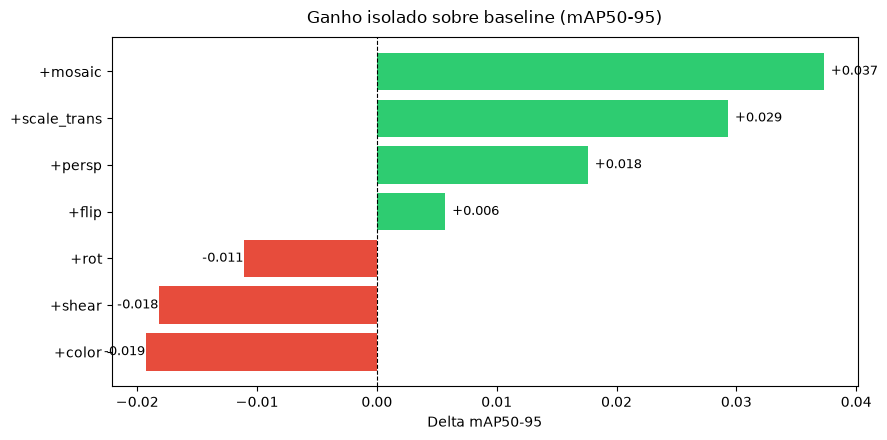

In [5]:
fig, ax = plt.subplots(figsize=(9, 4.5))
data = iso["gain_map50_95"].sort_values()
colors = ["#e74c3c" if v < 0 else "#2ecc71" for v in data]
bars = ax.barh(data.index, data.values, color=colors)
ax.axvline(0, color="black", linestyle="--", linewidth=0.8)
ax.set_title("Ganho isolado sobre baseline (mAP50-95)", fontsize=12, pad=10)
ax.set_xlabel("Delta mAP50-95")
for b in bars:
    w = b.get_width()
    ax.annotate(f"{w:+.3f}", (w, b.get_y() + b.get_height() / 2),
                xytext=(5 if w >= 0 else -30, 0), textcoords="offset points", va="center", fontsize=9)
plt.tight_layout()
plt.show()

## 2. Impacto Conjunto e Leave-One-Out (-x vs all)

Quando removemos $x$ do pacote completo:
- Se $\Delta < 0$: a transformação **fazia falta** (positiva para o conjunto).
- Se $\Delta > 0$: remover a transformação **melhorou** o resultado (ela estava atrapalhando as outras).

In [6]:
all_val = df.loc["all", "mAP50_95_last5"]
loo = df[df.index.str.startswith("-")].copy()
loo["impact_removal"] = loo["mAP50_95_last5"] - all_val
loo[["mAP50_last5", "mAP50_95_last5", "impact_removal"]].sort_values("impact_removal").round(4)

,mAP50_last5,mAP50_95_last5,impact_removal
config,,,
-color,0.3112,0.1019,-0.0321
-flip,0.3456,0.1249,-0.0091
-shear,0.3564,0.1265,-0.0075
-persp,0.3791,0.1312,-0.0028
-scale_trans,0.3820,0.1368,0.0028
-mosaic,0.3833,0.1382,0.0042
-rot,0.3548,0.1428,0.0088


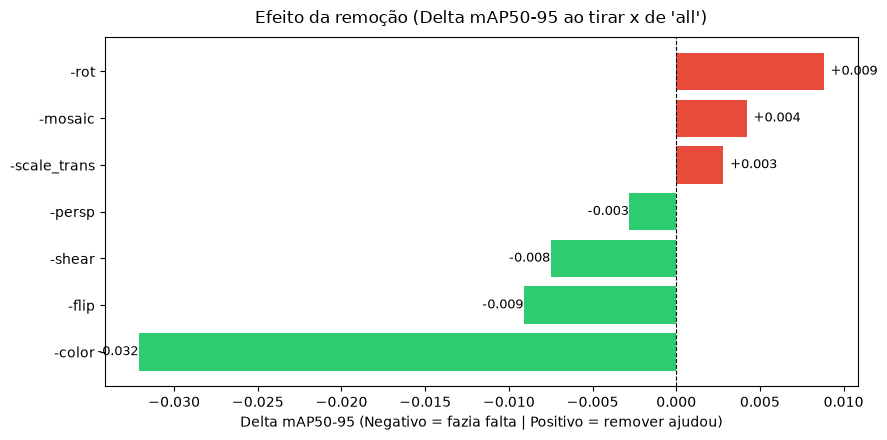

In [7]:
fig, ax = plt.subplots(figsize=(9, 4.5))
data_loo = loo["impact_removal"].sort_values()
# Se remover piorou (<0), a técnica era boa (verde). Se remover melhorou (>0), a técnica atrapalhava (vermelho).
colors_loo = ["#2ecc71" if v < 0 else "#e74c3c" for v in data_loo]
bars = ax.barh(data_loo.index, data_loo.values, color=colors_loo)
ax.axvline(0, color="black", linestyle="--", linewidth=0.8)
ax.set_title("Efeito da remoção (Delta mAP50-95 ao tirar x de 'all')", fontsize=12, pad=10)
ax.set_xlabel("Delta mAP50-95 (Negativo = fazia falta | Positivo = remover ajudou)")
for b in bars:
    w = b.get_width()
    ax.annotate(f"{w:+.3f}", (w, b.get_y() + b.get_height() / 2),
                xytext=(5 if w >= 0 else -30, 0), textcoords="offset points", va="center", fontsize=9)
plt.tight_layout()
plt.show()

## 3. Conclusão e Diretrizes para o Treino Final

1. **Mosaic e Scale/Translate**: foram os maiores ganhadores individuais (`+mosaic`: +0.078 mAP50, `+scale_trans`: +0.065 mAP50). Fundamentais em datasets pequenos.
2. **Perspectiva (`persp`)**: melhora o mAP isolado de forma consistente (+0.018 mAP50-95) e combina bem com fotos de calçadas em ângulo.
3. **Cor (`color`)**: isolada não ajuda, mas no conjunto é crítica (-color teve a maior queda de desempenho: -0.032 mAP50-95). Evita overfitting em iluminação específica.
4. **Rotação (`rot` - $\pm 10^\circ$) e o Trade-off Operacional**:
   - *Comportamento estático na métrica:* isoladamente, causou leve retração no mAP50-95 (-0.011) por desalinhar ligeiramente retângulos de objetos verticais (postes/troncos).
   - *Necessidade em campo (Mobile Edge):* em auditoria real com smartphone na mão de pedestres, o aparelho oscila e inclina continuamente no passo.
   - *Decisão de Engenharia:* **Adotada**. O leve custo na métrica estática é compensado pela tolerância a trepidação e inclinação angular em tempo real, evitando falsos negativos em campo.
5. **Cisalhamento (`shear`)**: **_Descartado_** (-0.018 mAP50-95). Causa distorções trapezoidais não naturais que deformam o formato de lixeiras e buracos sem ganho operacional.

**Decisão para o treino final**:
- **Adotados**: `mosaic=1.0`, `scale=0.5`, `translate=0.1`, `perspective=0.0005`, `fliplr=0.5`, `hsv` (h=0.015, s=0.7, v=0.4) e rotação suave `degrees=10.0` (requisito de campo móvel).
- **Descartados**: `shear=0.0` (deformação excessiva sem valor prático).
